In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install ucimlrepo -q

import pandas as pd
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=697)
X = data.data.features
y = data.data.targets

df = X.copy()
df["Target"] = y["Target"]

print(df.shape)
print(df["Target"].value_counts())

(4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [3]:
df = df[df["Target"] != "Enrolled"].reset_index(drop=True)
df["abandon"] = (df["Target"] == "Dropout").astype(int)

print(df.shape)
print(df["abandon"].value_counts(normalize=True).round(3))

(3630, 38)
abandon
0    0.609
1    0.391
Name: proportion, dtype: float64


In [4]:
print("Colonnes :", df.shape[1], "| Lignes :", df.shape[0])
print("\nValeurs manquantes (total) :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
print("\nTypes :")
print(df.dtypes.value_counts())
print("\nListe des colonnes :")
for c in df.columns:
    print("-", c)

Colonnes : 38 | Lignes : 3630

Valeurs manquantes (total) : 0
Doublons : 0

Types :
int64      30
float64     7
object      1
Name: count, dtype: int64

Liste des colonnes :
- Marital Status
- Application mode
- Application order
- Course
- Daytime/evening attendance
- Previous qualification
- Previous qualification (grade)
- Nacionality
- Mother's qualification
- Father's qualification
- Mother's occupation
- Father's occupation
- Admission grade
- Displaced
- Educational special needs
- Debtor
- Tuition fees up to date
- Gender
- Scholarship holder
- Age at enrollment
- International
- Curricular units 1st sem (credited)
- Curricular units 1st sem (enrolled)
- Curricular units 1st sem (evaluations)
- Curricular units 1st sem (approved)
- Curricular units 1st sem (grade)
- Curricular units 1st sem (without evaluations)
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular 

In [5]:
df.describe().T[["min", "max", "mean"]].round(2)

,min,max,mean
Marital Status,1.00,6.00,1.18
Application mode,1.00,57.00,18.42
Application order,0.00,6.00,1.75
Course,33.00,9991.00,8853.98
Daytime/evening attendance,0.00,1.00,0.89
Previous qualification,1.00,43.00,4.53
Previous qualification (grade),95.00,190.00,132.92
Nacionality,1.00,109.00,1.83
Mother's qualification,1.00,44.00,19.99
Father's qualification,1.00,44.00,22.57


In [6]:
from sklearn.model_selection import train_test_split

feat_sem1 = [c for c in df.columns if "1st sem" in c]
feat_sem2 = [c for c in df.columns if "2nd sem" in c]
cible = ["Target", "abandon"]

feat_A = [c for c in df.columns if c not in feat_sem1 + feat_sem2 + cible]
feat_B = feat_A + feat_sem1
feat_C = feat_B + feat_sem2

print("Variables A, B, C :", len(feat_A), len(feat_B), len(feat_C))

train, test = train_test_split(
    df, test_size=0.2, stratify=df["abandon"], random_state=42
)
print(train.shape, test.shape)
print("Abandons train :", round(train["abandon"].mean(), 3))
print("Abandons test  :", round(test["abandon"].mean(), 3))

Variables A, B, C : 24 30 36
(2904, 38) (726, 38)
Abandons train : 0.392
Abandons test  : 0.391


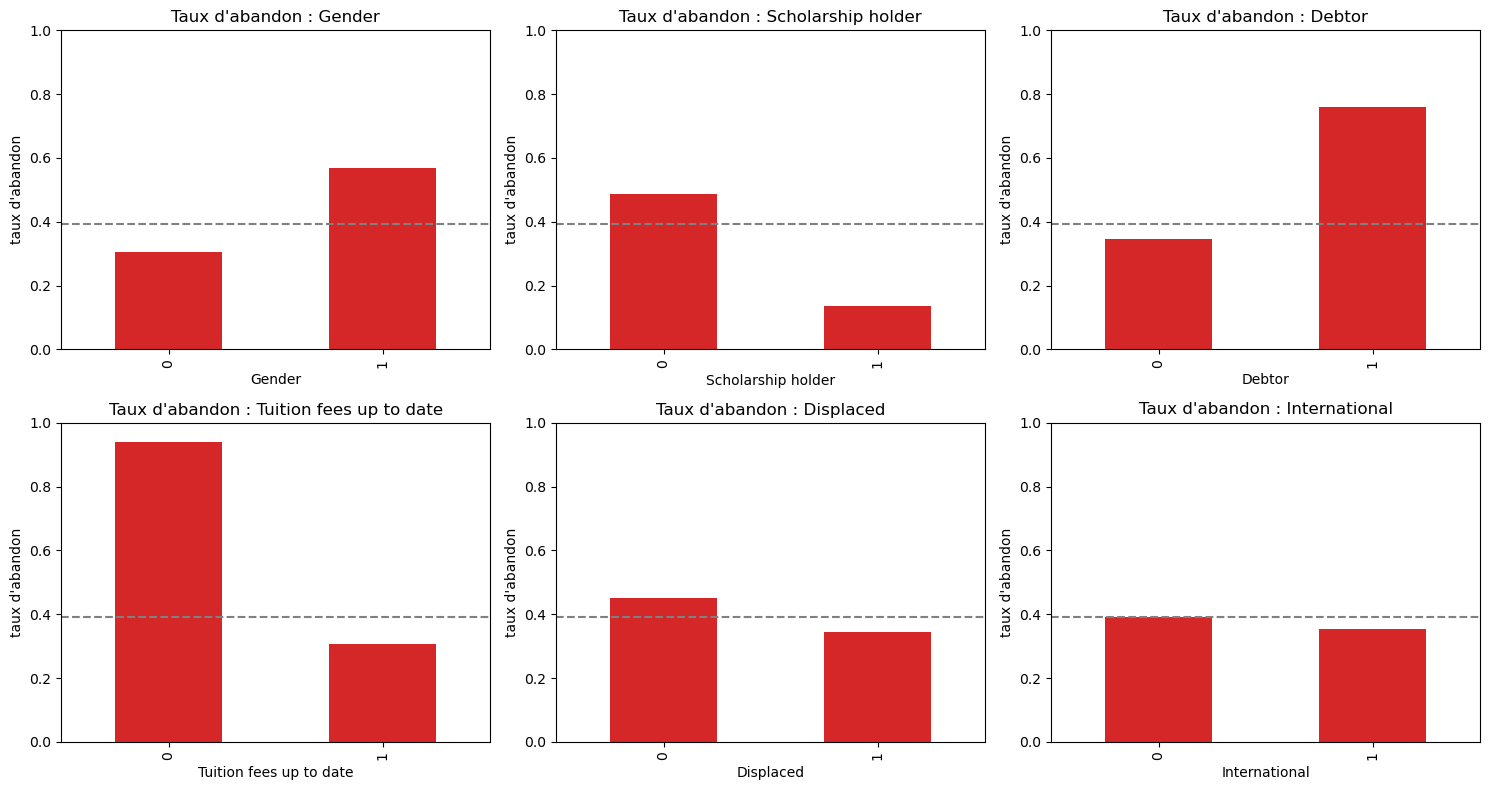

In [7]:
import matplotlib.pyplot as plt

cols = ["Gender", "Scholarship holder", "Debtor",
        "Tuition fees up to date", "Displaced", "International"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cols):
    train.groupby(c)["abandon"].mean().plot.bar(ax=ax, color="tab:red")
    ax.set_title(f"Taux d'abandon : {c}")
    ax.set_ylabel("taux d'abandon")
    ax.set_ylim(0, 1)
    ax.axhline(train["abandon"].mean(), color="gray", linestyle="--")
plt.tight_layout()
plt.show()

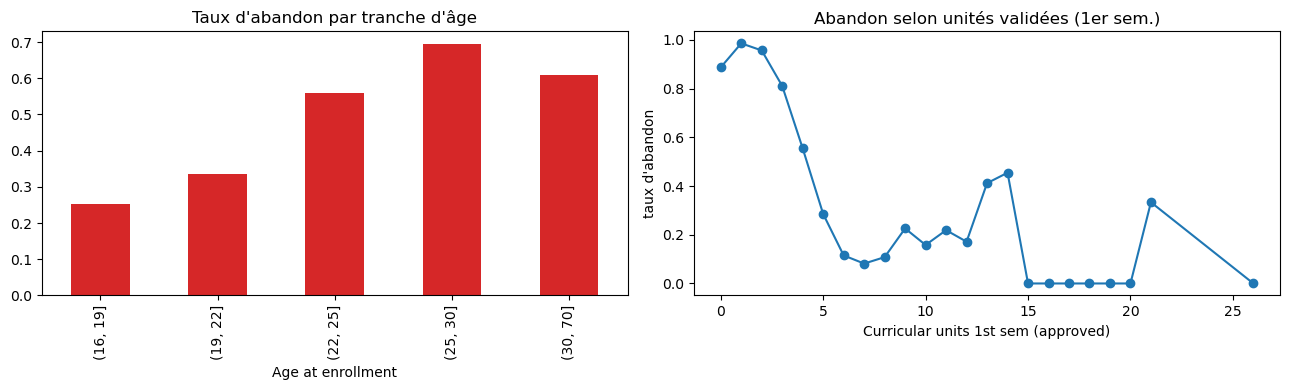

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

tranches = pd.cut(train["Age at enrollment"], [16, 19, 22, 25, 30, 70])
train.groupby(tranches, observed=True)["abandon"].mean().plot.bar(ax=axes[0], color="tab:red")
axes[0].set_title("Taux d'abandon par tranche d'âge")

train.groupby("Curricular units 1st sem (approved)")["abandon"].mean().plot(marker="o", ax=axes[1])
axes[1].set_title("Abandon selon unités validées (1er sem.)")
axes[1].set_ylabel("taux d'abandon")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score

cat_all = ["Marital Status", "Application mode", "Course", "Previous qualification",
           "Nacionality", "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]

scenarios = {"A": feat_A, "B": feat_B, "C": feat_C}
y_train = train["abandon"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "F1": make_scorer(f1_score, zero_division=0),
    "Rappel": make_scorer(recall_score, zero_division=0),
    "ROC-AUC": "roc_auc",
}
#Pipeline : une chaîne qui prépare les données puis lance le modèle.
def construire(modele, feats):
    cats = [c for c in cat_all if c in feats]
    nums = [c for c in feats if c not in cats]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
        ("num", StandardScaler(), nums),
    ])
    return Pipeline([("prep", prep), ("modele", modele)])

resultats = []
for nom, feats in scenarios.items():
    for nom_modele, modele in [
        ("Référence naïve", DummyClassifier(strategy="most_frequent")),
        ("Régression logistique", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]:
        pipe = construire(modele, feats)
        s = cross_validate(pipe, train[feats], y_train, cv=cv, scoring=scoring)
        resultats.append({"Scénario": nom, "Modèle": nom_modele,
                          "F1": s["test_F1"].mean(),
                          "Rappel": s["test_Rappel"].mean(),
                          "ROC-AUC": s["test_ROC-AUC"].mean()})

print(pd.DataFrame(resultats).round(3).to_string(index=False))

Scénario                Modèle    F1  Rappel  ROC-AUC
       A       Référence naïve 0.000   0.000    0.500
       A Régression logistique 0.713   0.727    0.848
       B       Référence naïve 0.000   0.000    0.500
       B Régression logistique 0.848   0.843    0.932
       C       Référence naïve 0.000   0.000    0.500
       C Régression logistique 0.866   0.858    0.945


In [ ]:
# Teste Random Forest et XGBoost dans les 3 scénarios (A, B, C) avec la
# validation croisée sur train, puis ajoute leurs scores (F1, rappel, ROC-AUC)

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

poids = (y_train == 0).sum() / (y_train == 1).sum()

nouveaux = [
    ("Random Forest", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)),
    ("XGBoost", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=poids, eval_metric="logloss",
        random_state=42, n_jobs=-1)),
]

for nom, feats in scenarios.items():
    for nom_modele, modele in nouveaux:
        pipe = construire(modele, feats)
        s = cross_validate(pipe, train[feats], y_train, cv=cv, scoring=scoring)
        resultats.append({"Scénario": nom, "Modèle": nom_modele,
                          "F1": s["test_F1"].mean(),
                          "Rappel": s["test_Rappel"].mean(),
                          "ROC-AUC": s["test_ROC-AUC"].mean()})

tableau = pd.DataFrame(resultats).round(3)
print(tableau.sort_values(["Scénario", "F1"], ascending=[True, False]).to_string(index=False))

Scénario                Modèle    F1  Rappel  ROC-AUC
       A               XGBoost 0.724   0.719    0.852
       A Régression logistique 0.713   0.727    0.848
       A         Random Forest 0.691   0.620    0.846
       A       Référence naïve 0.000   0.000    0.500
       B Régression logistique 0.848   0.843    0.932
       B               XGBoost 0.848   0.832    0.934
       B         Random Forest 0.837   0.777    0.928
       B       Référence naïve 0.000   0.000    0.500
       C Régression logistique 0.866   0.858    0.945
       C               XGBoost 0.865   0.836    0.946
       C         Random Forest 0.862   0.807    0.946
       C       Référence naïve 0.000   0.000    0.500


In [ ]:
# Cherche les meilleurs réglages de chaque modèle dans chaque scénario :
# pour chaque cas, teste 10 combinaisons tirées au hasard avec la validation
# croisée sur train, garde la meilleure (selon le F1) dans "meilleurs", et
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

grilles = {
    "Régression logistique": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"modele__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
        {"modele__n_estimators": [200, 300, 500],
         "modele__max_depth": [None, 6, 10, 15],
         "modele__min_samples_leaf": [1, 3, 5, 10],
         "modele__max_features": ["sqrt", 0.3, 0.5]}),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=poids, eval_metric="logloss",
                      random_state=42, n_jobs=-1),
        {"modele__n_estimators": [200, 300, 500],
         "modele__learning_rate": [0.02, 0.05, 0.1],
         "modele__max_depth": [2, 3, 4, 6],
         "modele__subsample": [0.7, 0.85, 1.0],
         "modele__colsample_bytree": [0.5, 0.7, 1.0]}),
}

meilleurs = {}
regles = []
for nom, feats in scenarios.items():
    for nom_modele, (modele, grille) in grilles.items():
        recherche = RandomizedSearchCV(
            construire(modele, feats), grille,
            n_iter=min(10, len(ParameterGrid(grille))),
            scoring=scoring, refit="F1", cv=cv,
            random_state=42, n_jobs=1)
        recherche.fit(train[feats], y_train)
        i = recherche.best_index_
        meilleurs[(nom, nom_modele)] = recherche.best_estimator_
        regles.append({"Scénario": nom, "Modèle": nom_modele,
                       "F1": recherche.cv_results_["mean_test_F1"][i],
                       "Rappel": recherche.cv_results_["mean_test_Rappel"][i],
                       "ROC-AUC": recherche.cv_results_["mean_test_ROC-AUC"][i]})

reglage = pd.DataFrame(regles).round(3)
print(reglage.sort_values(["Scénario", "F1"], ascending=[True, False]).to_string(index=False))

In [ ]:
# Entraîne les 4 modèles (réglages de base) sur train pour chaque scénario A/B/C,
# les évalue sur test (F1, rappel, ROC-AUC), garde les pipelines dans "finaux"
# et exporte le tableau des résultats dans resultats_test.csv.
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

modeles = {
    "Référence naïve": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=poids, eval_metric="logloss",
        random_state=42, n_jobs=-1),
}

y_test = test["abandon"]
finaux = {}
res_test = []

for nom, feats in scenarios.items():
    for nom_modele, modele in modeles.items():
        pipe = construire(clone(modele), feats)
        pipe.fit(train[feats], y_train)
        pred = pipe.predict(test[feats])
        proba = pipe.predict_proba(test[feats])[:, 1]
        finaux[(nom, nom_modele)] = pipe
        res_test.append({"Scénario": nom, "Modèle": nom_modele,
                         "F1": f1_score(y_test, pred, zero_division=0),
                         "Rappel": recall_score(y_test, pred, zero_division=0),
                         "ROC-AUC": roc_auc_score(y_test, proba)})

final = pd.DataFrame(res_test).round(3)
print(final.sort_values(["Scénario", "F1"], ascending=[True, False]).to_string(index=False))
final.to_csv("resultats_test.csv", index=False)

In [ ]:
# Évalue sur test les modèles réglés ("meilleurs") pour chaque scénario A/B/C :
# F1, rappel, ROC-AUC et PR-AUC (seuil 0,5), puis exporte le tableau
# dans resultats_test_regles.csv.
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (f1_score, recall_score, roc_auc_score,
                             average_precision_score)

y_test = test["abandon"]
lignes = []
for (sc, nom_modele), pipe in meilleurs.items():
    feats = scenarios[sc]
    proba = pipe.predict_proba(test[feats])[:, 1]
    pred = pipe.predict(test[feats])
    lignes.append({"Scénario": sc, "Modèle": nom_modele,
                   "F1": f1_score(y_test, pred),
                   "Rappel": recall_score(y_test, pred),
                   "ROC-AUC": roc_auc_score(y_test, proba),
                   "PR-AUC": average_precision_score(y_test, proba)})

tableau_test = pd.DataFrame(lignes).round(3)
print(tableau_test.sort_values(["Scénario", "F1"], ascending=[True, False])
      .to_string(index=False))
tableau_test.to_csv("resultats_test_regles.csv", index=False)

In [ ]:
# Pour chaque scénario : sélectionne le meilleur modèle réglé (F1 en validation
# croisée), puis fixe le seuil de décision le plus élevé qui garde un rappel >= 80 %
# sur les probabilités de validation croisée (train uniquement, sans toucher au test).
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

choix = {}
for sc, feats in scenarios.items():
    cand = reglage[reglage["Scénario"] == sc].sort_values("F1", ascending=False)
    nom_modele = cand.iloc[0]["Modèle"]
    pipe = meilleurs[(sc, nom_modele)]

    proba_cv = cross_val_predict(clone(pipe), train[feats], y_train,
                                 cv=cv, method="predict_proba")[:, 1]
    prec, rap, seuils = precision_recall_curve(y_train, proba_cv)
    ok = np.where(rap[:-1] >= 0.80)[0]
    # plus grand seuil qui garde un rappel >= 80 %
    seuil = float(seuils[ok[-1]]) if len(ok) else float(seuils[0])

    choix[sc] = {"modele": nom_modele, "pipe": pipe,
                 "feats": feats, "seuil": seuil}
    print(f"Scénario {sc} -> {nom_modele} | seuil = {seuil:.3f}")

In [ ]:
# Évalue sur test le modèle et le seuil retenus pour chaque scénario (dict "choix") :
# rappel, fausses alertes, précision, F1, ROC-AUC et PR-AUC, avec des intervalles
# de confiance à 95 % par bootstrap (1000 rééchantillonnages), puis exporte
# le tableau dans resultats_finaux.csv.

from sklearn.metrics import confusion_matrix, precision_score

rng = np.random.default_rng(42)
yt = y_test.values
resume = []

for sc, c in choix.items():
    proba = c["pipe"].predict_proba(test[c["feats"]])[:, 1]
    pred = (proba >= c["seuil"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()

    scores = []
    for _ in range(1000):
        i = rng.integers(0, len(yt), len(yt))
        if yt[i].min() == yt[i].max():
            continue
        scores.append([f1_score(yt[i], pred[i]),
                       recall_score(yt[i], pred[i]),
                       roc_auc_score(yt[i], proba[i]),
                       average_precision_score(yt[i], proba[i])])
    bas, haut = np.percentile(scores, [2.5, 97.5], axis=0)

    resume.append({
        "Scénario": sc, "Modèle": c["modele"],
        "Rappel": f"{tp/(tp+fn):.3f} [{bas[1]:.3f} ; {haut[1]:.3f}]",
        "Fausses alertes": round(fp / (fp + tn), 3),
        "Précision": round(precision_score(yt, pred), 3),
        "F1": f"{f1_score(yt, pred):.3f} [{bas[0]:.3f} ; {haut[0]:.3f}]",
        "ROC-AUC": f"{roc_auc_score(yt, proba):.3f} [{bas[2]:.3f} ; {haut[2]:.3f}]",
        "PR-AUC": f"{average_precision_score(yt, proba):.3f} [{bas[3]:.3f} ; {haut[3]:.3f}]",
    })

resultats_finaux = pd.DataFrame(resume)
print(resultats_finaux.to_string(index=False))
resultats_finaux.to_csv("resultats_finaux.csv", index=False)

In [ ]:
# Sauvegarde les 3 pipelines finaux (modele_A/B/C.joblib) et leur configuration
# (nom du modèle, seuil, variables d'entrée) dans config_modeles.json.
import json
import joblib

config = {}
for sc, c in choix.items():
    joblib.dump(c["pipe"], f"modele_{sc}.joblib")
    config[sc] = {"modele": c["modele"], "seuil": c["seuil"],
                  "variables": c["feats"]}

with open("config_modeles.json", "w") as f:
    json.dump(config, f, indent=2)
print("3 modèles et la config sauvegardés.")

In [ ]:
# Recharge les 3 modèles et la config, teste une prédiction sur 3 étudiants
# et affiche les versions des bibliothèques à fixer dans requirements.txt.
import joblib, json, sklearn, xgboost

cfg = json.load(open("config_modeles.json"))
for sc in "ABC":
    m = joblib.load(f"modele_{sc}.joblib")
    X = test[cfg[sc]["variables"]].head(3)
    print(sc, cfg[sc]["modele"], m.predict_proba(X)[:, 1].round(3),
          "seuil", round(cfg[sc]["seuil"], 3))

print(f"scikit-learn=={sklearn.__version__}")
print(f"xgboost=={xgboost.__version__}")
print(f"pandas=={pd.__version__}")
print(f"joblib=={joblib.__version__}")

In [ ]:
# Calcule une valeur par défaut pour chaque variable du scénario C (mode pour
# les catégorielles, médiane pour les numériques, sur train) et l'exporte dans
# defaults.json pour compléter les champs non saisis dans l'application.
import json

defaults = {}
for c in feat_C:
    if c in cat_all:
        defaults[c] = int(train[c].mode().iloc[0])
    else:
        defaults[c] = float(train[c].median())

with open("defaults.json", "w", encoding="utf-8") as f:
    json.dump(defaults, f, indent=2)
print(len(defaults), "valeurs par défaut sauvegardées")

In [ ]:
# Explique le XGBoost réglé avec SHAP (scénarios A et B) : refait le prétraitement
# en encodage dense, entraîne le modèle sur train, calcule les valeurs SHAP sur
# test et affiche les 12 variables qui influencent le plus le risque d'abandon.
from sklearn.base import clone

def shap_dense(sc):
    feats = scenarios[sc]
    modele = clone(meilleurs[(sc, "XGBoost")].named_steps["modele"])
    cats = [c for c in cat_all if c in feats]
    nums = [c for c in feats if c not in cats]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
        ("num", StandardScaler(), nums)])
    Xtr = prep.fit_transform(train[feats])
    Xte = prep.transform(test[feats])
    noms = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    modele.fit(Xtr, y_train)
    print(f"Scénario {sc} : F1 test (seuil 0.5) =",
          round(f1_score(y_test, modele.predict(Xte)), 3))
    sv = shap.TreeExplainer(modele).shap_values(Xte)
    shap.summary_plot(sv, Xte, feature_names=noms, max_display=12, show=False)
    plt.title(f"SHAP, XGBoost (encodage dense), scénario {sc}")
    plt.tight_layout()
    plt.show()

shap_dense("A")
shap_dense("B")